In [ ]:
import pandas as pd
import numpy as np

# Load expression data
ec = pd.read_csv("GSE157103_genes.ec.tsv.gz",
                 sep="\t", index_col=0)

tpm = pd.read_csv("GSE157103_genes.tpm.tsv.gz",
                  sep="\t", index_col=0)

# Basic dimensions
print("EC dimensions:", ec.shape)
print("TPM dimensions:", tpm.shape)

# First few rows
print("\nEC:")
print(ec.head())

print("\nTPM:")
print(tpm.head())

# Missing values
print("\nMissing values:")
print("EC:", ec.isnull().sum().sum())
print("TPM:", tpm.isnull().sum().sum())

# Duplicate genes
print("\nDuplicate genes:")
print("EC:", ec.index.duplicated().sum())
print("TPM:", tpm.index.duplicated().sum())

# Duplicate samples
print("\nDuplicate samples:")
print("EC:", ec.columns.duplicated().sum())
print("TPM:", tpm.columns.duplicated().sum())

# Expression value statistics
print("\nEC statistics:")
print(ec.describe().T)

print("\nTPM statistics:")
print(tpm.describe().T)

EC dimensions: (19472, 126)
TPM dimensions: (19472, 126)

EC:
            C1     C2     C3     C4     C5     C6     C7    C8     C9    C10  \
#symbol                                                                        
A1BG     29.01  11.04  15.54  23.33  10.19  13.22  26.56  6.88  27.64   8.13   
A1CF      0.00   0.00   0.00   1.00   0.00   0.00   1.16  0.00   1.00   0.00   
A2M      17.00   7.00   2.00   6.00   0.00   7.00  17.00  7.00  64.00  15.00   
A2ML1     3.00   0.00   1.06   4.06   3.07   2.96   2.01  0.93   0.99   0.93   
A3GALT2   1.00   0.00   0.00   0.00   1.00   0.00   1.00  0.00  11.00   3.00   

         ...   NC17   NC18   NC19   NC20   NC21   NC22   NC23  NC24   NC25  \
#symbol  ...                                                                 
A1BG     ...  24.08  33.15  25.97  14.76  28.75  32.32  63.20  51.0  235.4   
A1CF     ...   0.00   0.00   0.00   1.00   1.00   0.00   0.00   0.0    0.0   
A2M      ...   6.00   8.00  16.00   1.00   4.00   3.00   3.00  25

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import gzip
import csv
from io import BytesIO, StringIO
import re

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 20)

In [ ]:
base_url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE157nnn/GSE157103/suppl/"

# Load Expected Counts
ec_url = base_url + "GSE157103_genes.ec.tsv.gz"
ec = pd.read_csv(ec_url, sep="\t", index_col=0)

# Load TPM
tpm_url = base_url + "GSE157103_genes.tpm.tsv.gz"
tpm = pd.read_csv(tpm_url, sep="\t", index_col=0)

print("Expected Counts shape:", ec.shape)
print("TPM shape:", tpm.shape)

display(ec.head())
display(tpm.head())

Expected Counts shape: (19472, 126)
TPM shape: (19472, 126)


,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,C15,C16,C17,C18,C19,C20,C21,C22,C23,C24,C25,C26,C27,C28,C29,C30,C31,C32,C33,C34,C35,C36,C37,C38,C39,C40,C41,C42,C43,C44,C45,C46,C47,C48,C49,C50,C51,C52,C53,C55,C56,C57,C58,C59,C60,C61,C62,C63,C64,C65,C66,C67,C68,C69,C70,C71,C72,C73,C74,C75,C76,C77,C78,C79,C80,C82,C83,C84,C85,C86,C87,C89,C90,C91,C92,C93,C94,C95,C96,C97,C98,C99,C100,C101,C102,C103,NC1,NC2,NC3,NC4,NC5,NC6,NC7,NC8,NC9,NC10,NC11,NC12,NC13,NC14,NC15,NC16,NC17,NC18,NC19,NC20,NC21,NC22,NC23,NC24,NC25,NC26
#symbol,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A1BG,29.01,11.04,15.54,23.33,10.19,13.22,26.56,6.88,27.64,8.13,19.66,23.2,11.30,12.88,22.39,25.15,28.05,30.20,17.05,17.25,11.04,6.04,9.32,11.21,20.13,19.35,10.26,9.28,18.81,15.81,8.45,18.46,20.55,23.19,25.5,8.93,5.05,13.14,14.2,10.43,14.99,14.06,19.93,10.68,8.40,32.02,4.05,16.15,34.33,6.0,15.69,7.97,10.72,5.21,14.38,26.43,35.25,19.11,16.32,14.80,15.6,16.87,21.23,24.12,42.66,29.09,56.11,22.65,15.22,4.29,34.4,20.9,18.07,12.09,15.05,3.01,10.43,5.00,20.82,22.16,25.39,24.1,22.2,35.56,38.02,11.3,30.01,47.52,24.97,28.13,65.01,18.79,115.38,12.93,66.11,30.85,28.21,26.40,9.03,20.46,74.21,28.68,39.25,15.5,28.05,104.0,32.91,37.16,32.17,29.01,49.99,10.28,26.49,12.35,42.84,31.01,24.08,33.15,25.97,14.76,28.75,32.32,63.20,51.0,235.4,25.04
A1CF,0.00,0.00,0.00,1.00,0.00,0.00,1.16,0.00,1.00,0.00,3.00,0.0,0.00,0.00,0.00,1.04,2.00,0.00,2.93,0.00,0.00,0.00,1.51,0.96,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.0,1.00,0.00,0.00,0.0,0.00,0.00,1.00,0.00,0.00,0.00,1.00,1.05,0.00,0.00,0.0,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,1.07,0.0,1.0,0.00,2.00,0.00,0.00,0.00,0.97,0.98,1.93,0.00,0.0,0.0,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,1.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.0,0.00,1.18,0.00,0.00,0.85,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,0.00,0.00,0.0,0.0,0.00
A2M,17.00,7.00,2.00,6.00,0.00,7.00,17.00,7.00,64.00,15.00,33.00,11.0,6.00,17.00,5.00,47.00,9.00,27.00,8.00,5.00,0.00,5.00,2.00,8.00,9.00,11.00,20.00,13.00,2.00,10.00,37.00,3.00,24.00,10.00,71.0,6.00,3.00,6.00,27.0,11.00,15.00,26.00,0.00,9.00,12.00,8.00,3.00,7.00,9.00,1.0,13.01,0.00,37.00,7.01,11.00,23.01,9.00,8.00,14.00,8.00,4.0,1.00,3.00,6.00,0.00,37.00,20.00,17.00,5.00,10.00,9.0,1.0,12.00,10.00,11.00,1.00,14.00,3.00,5.00,8.00,13.00,3.0,4.0,21.00,12.00,5.0,5.00,3.00,2.00,11.00,18.00,14.00,2.00,2.00,30.00,3.00,11.00,12.00,1.00,4.00,4.00,1.00,6.00,5.0,1.00,23.0,7.00,4.00,4.00,6.00,4.00,2.00,5.00,9.00,3.29,8.00,6.00,8.00,16.00,1.00,4.00,3.00,3.00,25.0,5.0,42.00
A2ML1,3.00,0.00,1.06,4.06,3.07,2.96,2.01,0.93,0.99,0.93,2.01,0.0,1.05,2.69,0.00,0.00,1.25,2.31,1.44,0.00,0.00,0.00,0.00,1.04,2.07,0.00,1.00,2.98,2.00,1.07,0.00,0.00,4.05,0.00,3.8,0.00,2.01,1.01,0.0,0.00,0.00,1.00,0.00,0.00,2.09,0.00,1.93,1.00,2.13,0.0,0.00,1.22,4.99,1.00,5.19,0.99,0.00,0.00,0.00,2.21,0.0,0.00,1.00,0.00,0.00,0.00,1.00,1.01,0.00,1.02,1.0,1.0,1.50,0.00,0.96,0.00,0.00,0.00,0.00,0.00,3.33,0.0,0.0,1.01,0.00,2.0,0.83,2.05,3.00,0.00,2.00,1.15,0.00,4.15,0.00,0.00,0.00,2.37,1.05,3.96,0.00,0.00,2.00,0.0,1.00,1.0,2.00,0.00,0.00,1.06,0.00,0.00,0.99,0.00,2.98,0.00,1.04,0.00,0.00,2.01,2.00,1.94,1.02,0.0,0.0,0.00
A3GALT2,1.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00,11.00,3.00,1.00,23.0,0.00,13.00,2.00,3.00,0.00,1.00,0.00,3.00,6.00,1.00,1.00,2.00,0.00,10.00,3.00,6.00,2.00,0.00,0.00,4.00,4.00,2.00,4.0,1.00,2.00,4.00,0.0,1.00,4.00,6.00,2.00,0.00,3.00,1.00,8.00,5.00,0.00,0.0,0.00,0.00,0.00,0.00,3.00,3.00,0.00,1.00,0.00,2.00,1.0,2.00,8.00,9.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,2.0,5.00,0.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,3.0,0.0,0.00,0.00,2.0,6.00,1.00,11.00,1.00,0.00,2.00,0.00,2.00,8.00,1.00,1.00,1.00,0.00,1.00,0.00,1.00,1.00,4.0,0.00,0.0,0.00,3.00,0.00,5.00,0.00,0.00,7.00,1.00,0.00,3.00,3.00,0.00,1.00,0.00,0.00,0.00,0.00,1.0,0.0,0.00


,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,C15,C16,C17,C18,C19,C20,C21,C22,C23,C24,C25,C26,C27,C28,C29,C30,C31,C32,C33,C34,C35,C36,C37,C38,C39,C40,C41,C42,C43,C44,C45,C46,C47,C48,C49,C50,C51,C52,C53,C55,C56,C57,C58,C59,C60,C61,C62,C63,C64,C65,C66,C67,C68,C69,C70,C71,C72,C73,C74,C75,C76,C77,C78,C79,C80,C82,C83,C84,C85,C86,C87,C89,C90,C91,C92,C93,C94,C95,C96,C97,C98,C99,C100,C101,C102,C103,NC1,NC2,NC3,NC4,NC5,NC6,NC7,NC8,NC9,NC10,NC11,NC12,NC13,NC14,NC15,NC16,NC17,NC18,NC19,NC20,NC21,NC22,NC23,NC24,NC25,NC26
#symbol,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A1BG,0.49,0.29,0.26,0.45,0.17,0.21,0.49,0.12,0.51,0.10,0.38,0.45,0.18,0.23,0.42,0.41,0.63,0.47,0.33,0.32,0.18,0.09,0.18,0.22,0.29,0.42,0.16,0.18,0.35,0.23,0.15,0.34,0.35,0.36,0.26,0.18,0.20,0.29,0.19,0.22,0.19,0.24,0.29,0.22,0.14,0.53,0.08,0.19,0.48,0.08,0.21,0.25,0.25,0.09,0.28,0.42,0.39,0.33,0.22,0.25,0.21,0.29,0.38,0.40,0.64,0.37,0.58,0.52,0.27,0.07,0.52,0.46,0.24,0.23,0.17,0.05,0.19,0.08,0.28,0.39,0.47,0.35,0.29,0.60,0.65,0.20,0.40,0.60,0.34,0.37,0.81,0.37,1.61,0.19,0.78,0.33,0.30,0.33,0.12,0.20,0.89,0.32,0.44,0.21,0.31,0.89,0.45,0.47,0.40,0.33,0.58,0.12,0.31,0.16,0.59,0.34,0.37,0.33,0.25,0.20,0.40,0.30,0.70,0.75,2.80,0.22
A1CF,0.00,0.00,0.00,0.01,0.00,0.00,0.01,0.00,0.01,0.00,0.02,0.00,0.00,0.00,0.00,0.01,0.02,0.00,0.02,0.00,0.00,0.00,0.01,0.01,0.00,0.00,0.01,0.00,0.00,0.00,0.00,0.01,0.00,0.00,0.00,0.01,0.00,0.00,0.00,0.00,0.00,0.01,0.00,0.00,0.00,0.01,0.01,0.00,0.00,0.00,0.00,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.01,0.01,0.00,0.00,0.00,0.00,0.00,0.01,0.00,0.01,0.00,0.01,0.00,0.00,0.00,0.01,0.00,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
A2M,0.21,0.14,0.03,0.09,0.00,0.08,0.23,0.08,0.88,0.13,0.47,0.16,0.07,0.22,0.07,0.58,0.15,0.30,0.11,0.07,0.00,0.06,0.03,0.11,0.09,0.18,0.23,0.18,0.03,0.11,0.47,0.04,0.30,0.11,0.51,0.09,0.09,0.10,0.27,0.17,0.14,0.33,0.00,0.14,0.15,0.10,0.04,0.06,0.09,0.01,0.13,0.00,0.64,0.09,0.16,0.27,0.08,0.10,0.14,0.10,0.04,0.01,0.04,0.07,0.00,0.35,0.15,0.29,0.07,0.12,0.10,0.02,0.12,0.14,0.09,0.01,0.20,0.03,0.05,0.10,0.18,0.03,0.04,0.27,0.15,0.07,0.05,0.03,0.02,0.11,0.17,0.20,0.02,0.02,0.26,0.02,0.09,0.11,0.01,0.03,0.04,0.01,0.05,0.05,0.01,0.14,0.07,0.04,0.04,0.05,0.03,0.02,0.04,0.08,0.03,0.07,0.07,0.06,0.11,0.01,0.04,0.02,0.02,0.27,0.04,0.28
A2ML1,0.04,0.00,0.02,0.07,0.05,0.04,0.03,0.01,0.02,0.01,0.03,0.00,0.01,0.04,0.00,0.00,0.02,0.02,0.02,0.00,0.00,0.00,0.00,0.02,0.03,0.00,0.01,0.05,0.03,0.01,0.00,0.00,0.06,0.00,0.02,0.00,0.07,0.02,0.00,0.00,0.00,0.01,0.00,0.00,0.03,0.00,0.03,0.01,0.03,0.00,0.00,0.03,0.10,0.01,0.09,0.01,0.00,0.00,0.00,0.03,0.00,0.00,0.02,0.00,0.00,0.00,0.01,0.02,0.00,0.01,0.01,0.02,0.02,0.00,0.01,0.00,0.00,0.00,0.00,0.00,0.05,0.00,0.00,0.02,0.00,0.03,0.01,0.02,0.04,0.00,0.02,0.02,0.00,0.05,0.00,0.00,0.00,0.03,0.01,0.03,0.00,0.00,0.02,0.00,0.01,0.01,0.02,0.00,0.00,0.01,0.00,0.00,0.01,0.00,0.04,0.00,0.01,0.00,0.00,0.02,0.02,0.02,0.01,0.00,0.00,0.00
A3GALT2,0.07,0.00,0.00,0.00,0.07,0.00,0.07,0.00,0.79,0.15,0.08,1.75,0.00,0.93,0.15,0.19,0.00,0.06,0.00,0.22,0.37,0.06,0.07,0.15,0.00,0.87,0.18,0.45,0.15,0.00,0.00,0.29,0.26,0.12,0.16,0.08,0.31,0.35,0.00,0.08,0.19,0.39,0.11,0.00,0.19,0.06,0.60,0.23,0.00,0.00,0.00,0.00,0.00,0.00,0.23,0.19,0.00,0.07,0.00,0.13,0.05,0.14,0.56,0.58,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.17,0.26,0.00,0.04,0.00,0.00,0.00,0.05,0.00,0.00,0.17,0.00,0.00,0.00,0.14,0.31,0.05,0.58,0.05,0.00,0.15,0.00,0.12,0.37,0.04,0.04,0.05,0.00,0.04,0.00,0.04,0.04,0.21,0.00,0.00,0.00,0.15,0.00,0.23,0.00,0.00,0.32,0.05,0.00,0.13,0.18,0.00,0.04,0.00,0.00,0.00,0.00,0.06,0.00,0.00


In [ ]:
metadata_url = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE157nnn/GSE157103/matrix/"
    "GSE157103_series_matrix.txt.gz"
)

response = requests.get(metadata_url)
response.raise_for_status()

# Decompress the downloaded file
text = gzip.decompress(response.content).decode(
    "utf-8", errors="replace"
)

# Extract all sample-level metadata
metadata_rows = {}
key_counts = {}

for line in text.splitlines():

    if line.startswith("!Sample_"):

        fields = next(csv.reader([line], delimiter="\t"))

        key = fields[0].replace("!Sample_", "")
        values = fields[1:]

        # Handle repeated metadata fields
        if key in key_counts:
            key_counts[key] += 1
            key = f"{key}_{key_counts[key]}"
        else:
            key_counts[key] = 1

        metadata_rows[key] = values

# Convert into a DataFrame
meta = pd.DataFrame(metadata_rows)

print("Metadata shape:", meta.shape)
display(meta.head())

Metadata shape: (126, 62)


,title,geo_accession,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,characteristics_ch1,characteristics_ch1_2,characteristics_ch1_3,characteristics_ch1_4,characteristics_ch1_5,characteristics_ch1_6,characteristics_ch1_7,characteristics_ch1_8,characteristics_ch1_9,characteristics_ch1_10,characteristics_ch1_11,characteristics_ch1_12,characteristics_ch1_13,characteristics_ch1_14,characteristics_ch1_15,characteristics_ch1_16,characteristics_ch1_17,characteristics_ch1_18,characteristics_ch1_19,characteristics_ch1_20,characteristics_ch1_21,treatment_protocol_ch1,growth_protocol_ch1,molecule_ch1,extract_protocol_ch1,extract_protocol_ch1_2,taxid_ch1,description,description_2,description_3,data_processing,data_processing_2,data_processing_3,data_processing_4,data_processing_5,platform_id,contact_name,contact_email,contact_department,contact_institute,contact_address,contact_city,contact_state,contact_zip/postal_code,contact_country,data_row_count,instrument_model,library_selection,library_source,library_strategy,relation,relation_2,supplementary_file_1
0,COVID_01_39y_male_NonICU,GSM4753021,Public on Aug 29 2020,Aug 28 2020,Aug 29 2020,SRA,1,Leukocytes from whole blood,Homo sapiens,disease state: COVID-19,age (years): 39,Sex: male,icu: no,apacheii: 15,charlson score: 0,mechanical ventilation: yes,ventilator-free days: 0,dm: 0,hospital-free days post 45 day followup (days): 0,ferritin (ng/ml): 946,crp (mg/l): 73.1,ddimer (mg/l_feu): 1.3,procalcitonin (ng/ml): 36,lactate (mmol/l): 0.9,fibrinogen: 513,sofa: 8,associated controlled-vocabulary terms: DOID:0...,cell type: leukocyte,tissue of origin: whole blood,sample type: primary cells,N/A,N/A,total RNA,10mL of whole blood collected from patients wa...,TruSeq Stranded mRNA Library prep. Libraries w...,9606,C1,genes.ec.tsv,genes.tpm.tsv,Basecalling via the standard Illumina Pipeline...,Trimming/Filtering for adapters and low qualit...,Expression estimates via RSEM v1.3.0 under Pyt...,Genome_build: hg38,Supplementary_files_format_and_content: tab-de...,GPL24676,"Adolfo,Ariel,Jaitovich",jaitova@amc.edu,Molecular and Cellular Physiology,Albany Medical Center,47 New Scotland Av,Albany,NY,12208,USA,0,Illumina NovaSeq 6000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,SRA: https://www.ncbi.nlm.nih.gov/sra?term=SRX...,NONE
1,COVID_02_63y_male_NonICU,GSM4753022,Public on Aug 29 2020,Aug 28 2020,Aug 29 2020,SRA,1,Leukocytes from whole blood,Homo sapiens,disease state: COVID-19,age (years): 63,Sex: male,icu: no,apacheii: unknown,charlson score: 2,mechanical ventilation: no,ventilator-free days: 28,dm: 0,hospital-free days post 45 day followup (days)...,ferritin (ng/ml): 1060,crp (mg/l): unknown,ddimer (mg/l_feu): 1.03,procalcitonin (ng/ml): 0.37,lactate (mmol/l): unknown,fibrinogen: unknown,sofa: unknown,associated controlled-vocabulary terms: DOID:0...,cell type: leukocyte,tissue of origin: whole blood,sample type: primary cells,N/A,N/A,total RNA,10mL of whole blood collected from patients wa...,TruSeq Stranded mRNA Library prep. Libraries w...,9606,C2,genes.ec.tsv,genes.tpm.tsv,Basecalling via the standard Illumina Pipeline...,Trimming/Filtering for adapters and low qualit...,Expression estimates via RSEM v1.3.0 under Pyt...,Genome_build: hg38,Supplementary_files_format_and_content: tab-de...,GPL24676,"Adolfo,Ariel,Jaitovich",jaitova@amc.edu,Molecular and Cellular Physiology,Albany Medical Center,47 New Scotland Av,Albany,NY,12208,USA,0,Illumina NovaSeq 6000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,SRA: https://www.ncbi.nlm.nih.gov/sra?term=SRX...,NONE
2,COVID_03_33y_male_NonICU,GSM4753023,Public on Aug 29 2020,Aug 28 2020,Aug 29 2020,SRA,1,Leukocytes from whole blood,Homo sapiens,disease state: COVID-19,age (years): 33,Sex: male,icu: no,apacheii: unknown,charlson score: 2,mechanical ventilation: no,ventilator-free days: 28,dm: 1,hospital-free days post 45 day followup (days)...,ferritin (ng

In [ ]:
def get_sample_id(title):

    title = str(title)

    # Non-COVID samples
    if title.startswith("NONCOVID"):
        number = re.search(r"NONCOVID_(\d+)", title).group(1)
        return "NC" + str(int(number))

    # COVID samples
    elif title.startswith("COVID"):
        number = re.search(r"COVID_(\d+)", title).group(1)
        return "C" + str(int(number))

    return None


meta["sample_id"] = meta["title"].apply(get_sample_id)

# Use expression sample IDs as the metadata index
meta = meta.set_index("sample_id")

# Check sample matching
print("Expression samples:", len(ec.columns))
print("Metadata samples:", len(meta))

print("Missing metadata samples:")
print(set(ec.columns) - set(meta.index))

print("Extra metadata samples:")
print(set(meta.index) - set(ec.columns))

# Reorder metadata to match expression matrix columns
meta = meta.loc[ec.columns]

print("\nSamples aligned:", list(meta.index) == list(ec.columns))

Expression samples: 126
Metadata samples: 126
Missing metadata samples:
set()
Extra metadata samples:
set()

Samples aligned: True


In [ ]:
# Transpose expression matrices
ec_samples = ec.T
tpm_samples = tpm.T

# Add prefixes to distinguish expression values
ec_samples.columns = ["EC_" + str(gene) for gene in ec_samples.columns]
tpm_samples.columns = ["TPM_" + str(gene) for gene in tpm_samples.columns]

# Combine expected counts and TPM
expression = pd.concat([ec_samples, tpm_samples], axis=1)

# Combine metadata and expression
data = pd.concat([meta, expression], axis=1)

print("Combined dataset shape:", data.shape)

display(data.head())

Combined dataset shape: (126, 39006)


,title,geo_accession,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,characteristics_ch1,characteristics_ch1_2,characteristics_ch1_3,characteristics_ch1_4,characteristics_ch1_5,characteristics_ch1_6,characteristics_ch1_7,characteristics_ch1_8,characteristics_ch1_9,characteristics_ch1_10,characteristics_ch1_11,characteristics_ch1_12,characteristics_ch1_13,characteristics_ch1_14,characteristics_ch1_15,characteristics_ch1_16,characteristics_ch1_17,characteristics_ch1_18,characteristics_ch1_19,characteristics_ch1_20,characteristics_ch1_21,treatment_protocol_ch1,growth_protocol_ch1,molecule_ch1,extract_protocol_ch1,extract_protocol_ch1_2,taxid_ch1,description,description_2,description_3,data_processing,data_processing_2,data_processing_3,data_processing_4,data_processing_5,platform_id,contact_name,contact_email,contact_department,contact_institute,contact_address,contact_city,contact_state,contact_zip/postal_code,contact_country,data_row_count,instrument_model,library_selection,library_source,library_strategy,relation,relation_2,supplementary_file_1,EC_A1BG,EC_A1CF,EC_A2M,EC_A2ML1,EC_A3GALT2,EC_A4GALT,EC_A4GNT,EC_AAAS,EC_AACS,EC_AADAC,EC_AADACL2,EC_AADACL3,EC_AADACL4,EC_AADAT,EC_AAGAB,EC_AAK1,EC_AAMDC,EC_AAMP,EC_AANAT,EC_AAR2,EC_AARD,EC_AARS1,EC_AARS2,EC_AARSD1,EC_AASDH,EC_AASDHPPT,EC_AASS,EC_AATF,EC_AATK,EC_ABAT,EC_ABCA1,EC_ABCA10,EC_ABCA12,EC_ABCA13,EC_ABCA2,EC_ABCA3,EC_ABCA4,EC_ABCA5,EC_ABCA6,EC_ABCA7,EC_ABCA8,EC_ABCA9,EC_ABCB1,EC_ABCB10,EC_ABCB11,EC_ABCB4,EC_ABCB5,EC_ABCB6,EC_ABCB7,EC_ABCB8,EC_ABCB9,EC_ABCC1,EC_ABCC10,EC_ABCC11,EC_ABCC12,EC_ABCC2,EC_ABCC3,EC_ABCC4,EC_ABCC5,EC_ABCC6,EC_ABCC8,EC_ABCC9,EC_ABCD1,EC_ABCD2,EC_ABCD3,EC_ABCD4,EC_ABCE1,EC_ABCF1,EC_ABCF2,EC_ABCF2-H2BE1,EC_ABCF3,EC_ABCG1,EC_ABCG2,EC_ABCG4,EC_ABCG5,EC_ABCG8,EC_ABHD1,EC_ABHD10,EC_ABHD11,EC_ABHD12,EC_ABHD12B,EC_ABHD13,EC_ABHD14A,EC_ABHD14A-ACY1,EC_ABHD14B,EC_ABHD15,EC_ABHD16A,EC_ABHD16B,EC_ABHD17A,EC_ABHD17B,EC_ABHD17C,EC_ABHD18,EC_ABHD2,EC_ABHD3,EC_ABHD4,EC_ABHD5,EC_ABHD6,EC_ABHD8,EC_ABI1,EC_ABI2,EC_ABI3,EC_ABI3BP,EC_ABITRAM,EC_ABL1,EC_ABL2,EC_ABLIM1,EC_ABLIM2,EC_ABLIM3,EC_ABO,EC_ABR,EC_ABRA,EC_ABRACL,EC_ABRAXAS1,EC_ABRAXAS2,EC_ABT1,EC_ABTB1,EC_ABTB2,EC_ACAA1,EC_ACAA2,EC_ACACA,EC_ACACB,EC_ACAD10,EC_ACAD11,EC_ACAD8,EC_ACAD9,EC_ACADL,EC_ACADM,EC_ACADS,EC_ACADSB,EC_ACADVL,EC_ACAN,EC_ACAP1,EC_ACAP2,EC_ACAP3,EC_ACAT1,EC_ACAT2,EC_ACBD3,EC_ACBD4,EC_ACBD5,EC_ACBD6,EC_ACBD7,EC_ACCS,EC_ACCSL,EC_ACD,EC_ACE,EC_ACE2,EC_ACER1,EC_ACER2,EC_ACER3,EC_ACHE,EC_ACIN1,EC_ACKR1,EC_ACKR2,EC_ACKR3,EC_ACKR4,EC_ACLY,EC_ACMSD,EC_ACO1,EC_ACO2,EC_ACOD1,EC_ACOT1,EC_ACOT11,EC_ACOT12,EC_ACOT13,EC_ACOT2,EC_ACOT4,EC_ACOT6,EC_ACOT7,EC_ACOT8,EC_ACOT9,EC_ACOX1,EC_ACOX2,EC_ACOX3,EC_ACOXL,EC_ACP1,EC_ACP2,EC_ACP3,EC_ACP4,EC_ACP5,EC_ACP6,EC_ACP7,EC_ACR,EC_ACRBP,EC_ACRV1,EC_ACSBG1,EC_ACSBG2,EC_ACSF2,EC_ACSF3,EC_ACSL1,EC_ACSL3,EC_ACSL4,EC_ACSL5,EC_ACSL6,EC_ACSM1,EC_ACSM2A,EC_ACSM2B,EC_ACSM3,EC_ACSM4,EC_ACSM5,EC_ACSM6,EC_ACSS1,EC_ACSS2,EC_ACSS3,EC_ACTA1,EC_ACTA2,EC_ACTB,EC_ACTBL2,EC_ACTC1,EC_ACTG1,EC_ACTG2,EC_ACTL10,EC_ACTL6A,EC_ACTL6B,EC_ACTL7A,EC_ACTL7B,EC_ACTL8,EC_ACTL9,EC_ACTN1,EC_ACTN2,EC_ACTN3,EC_ACTN4,EC_ACTR10,EC_ACTR1A,EC_ACTR1B,EC_ACTR2,EC_ACTR3,EC_ACTR3B,EC_ACTR3C,EC_ACTR5,EC_ACTR6,EC_ACTR8,EC_ACTRT1,EC_ACTRT2,EC_ACTRT3,EC_ACVR1,EC_ACVR1B,EC_ACVR1C,EC_ACVR2A,EC_ACVR2B,EC_ACVRL1,EC_ACY1,EC_ACY3,EC_ACYP1,EC_ACYP2,EC_ADA,EC_ADA2,EC_ADAD1,EC_ADAD2,EC_ADAL,EC_ADAM10,EC_ADAM11,EC_ADAM12,EC_ADAM15,EC_ADAM17,EC_ADAM18,EC_ADAM19,EC_ADAM2,EC_ADAM20,EC_ADAM21,EC_ADAM22,EC_ADAM23,EC_ADAM28,EC_ADAM29,EC_ADAM30,EC_ADAM32,EC_ADAM33,EC_ADAM7,EC_ADAM8,EC_ADAM9,EC_ADAMDEC1,EC_ADAMTS1,EC_ADAMTS10,EC_ADAMTS12,EC_ADAMTS13,EC_ADAMTS14,EC_ADAMTS15,EC_ADAMTS16,EC_ADAMTS17,EC_ADAMTS18,EC_ADAMTS19,EC_ADAMTS2,EC_ADAMTS20,EC_ADAMTS3,EC_ADAMTS4,EC_ADAMTS5,EC_ADAMTS6,EC_ADAMTS7,EC_ADAMTS8,EC_ADAMTS9,EC_ADAMTSL1,EC_ADAMTSL2,EC_ADAMTSL3,EC_ADAMTSL4,EC_ADAMTSL5,EC_ADAP1,EC_ADAP2,EC_ADAR,EC_ADARB1,EC_ADARB2,EC_ADAT1,EC_ADAT2,EC_ADAT3,EC_ADCK1,EC_ADCK2,EC_ADCK5,EC_ADCY1,EC_ADCY10,EC_AD

In [ ]:
# Disease classification
meta["Disease"] = np.where(
    meta["title"].str.startswith("NONCOVID"),
    "Non-COVID",
    "COVID"
)

# ICU classification
meta["ICU"] = pd.Series(index=meta.index, dtype="object")

meta.loc[meta["title"].str.endswith("NonICU"), "ICU"] = "Non-ICU"

meta.loc[
    meta["title"].str.endswith("ICU") &
    ~meta["title"].str.endswith("NonICU"),
    "ICU"
] = "ICU"

# Update combined dataset
data["Disease"] = meta["Disease"]
data["ICU"] = meta["ICU"]

print("Disease distribution:")
print(meta["Disease"].value_counts())

print("\nICU distribution:")
print(meta["ICU"].value_counts(dropna=False))

print("\nDisease vs ICU:")
print(pd.crosstab(meta["Disease"], meta["ICU"], dropna=False))

Disease distribution:
Disease
COVID        100
Non-COVID     26
Name: count, dtype: int64

ICU distribution:
ICU
ICU        66
Non-ICU    60
Name: count, dtype: int64

Disease vs ICU:
ICU        ICU  Non-ICU
Disease                
COVID       50       50
Non-COVID   16       10


In [ ]:
print("========== DATASET SUMMARY ==========")

print("\nExpected Counts:")
print(ec.shape)
print("Missing values:", ec.isnull().sum().sum())

print("\nTPM:")
print(tpm.shape)
print("Missing values:", tpm.isnull().sum().sum())

print("\nMetadata:")
print(meta.shape)
print("Missing values:", meta.isnull().sum().sum())

print("\nCombined dataset:")
print(data.shape)

print("\nDuplicate genes:", ec.index.duplicated().sum())
print("Duplicate samples:", ec.columns.duplicated().sum())

print("\nSample alignment:")
print(
    list(ec.columns) == list(tpm.columns)
    == list(meta.index)
    == list(data.index)
)

========== DATASET SUMMARY ==========

Expected Counts:
(19472, 126)
Missing values: 0

TPM:
(19472, 126)
Missing values: 0

Metadata:
(126, 64)
Missing values: 0

Combined dataset:
(126, 39008)

Duplicate genes: 0
Duplicate samples: 0

Sample alignment:
True


In [ ]:
print("Disease distribution:")
print(meta["Disease"].value_counts(dropna=False))

print("\nICU distribution:")
print(meta["ICU"].value_counts(dropna=False))

print("\nDisease vs ICU:")
print(pd.crosstab(meta["Disease"], meta["ICU"], dropna=False))

print("\nSample titles and assigned labels:")
display(meta[["title", "Disease", "ICU"]].head(15))

Disease distribution:
Disease
COVID        100
Non-COVID     26
Name: count, dtype: int64

ICU distribution:
ICU
ICU        66
Non-ICU    60
Name: count, dtype: int64

Disease vs ICU:
ICU        ICU  Non-ICU
Disease                
COVID       50       50
Non-COVID   16       10

Sample titles and assigned labels:


,title,Disease,ICU
C1,COVID_01_39y_male_NonICU,COVID,Non-ICU
C2,COVID_02_63y_male_NonICU,COVID,Non-ICU
C3,COVID_03_33y_male_NonICU,COVID,Non-ICU
C4,COVID_04_49y_male_NonICU,COVID,Non-ICU
C5,COVID_05_49y_male_NonICU,COVID,Non-ICU
C6,COVID_06_:y_male_NonICU,COVID,Non-ICU
C7,COVID_07_38y_female_NonICU,COVID,Non-ICU
C8,COVID_08_78y_male_ICU,COVID,ICU
C9,COVID_09_64y_female_ICU,COVID,ICU
C10,COVID_10_62y_male_ICU,COVID,ICU


In [ ]:
# Find metadata columns related to ICU or disease status
for col in meta.columns:
    if any(word in col.lower() for word in ["icu", "disease", "severity"]):
        print("\nColumn:", col)
        print(meta[col].value_counts(dropna=False))


Column: Disease
Disease
COVID        100
Non-COVID     26
Name: count, dtype: int64

Column: ICU
ICU
ICU        66
Non-ICU    60
Name: count, dtype: int64


Sample-level expression and sequencing depth

Overall sequencing depth summary:
count    1.260000e+02
mean     2.594082e+07
std      4.150307e+06
min      1.181037e+07
25%      2.351394e+07
50%      2.594485e+07
75%      2.814386e+07
max      4.213207e+07
Name: Total_EC, dtype: float64

Sequencing depth by disease group:
           count          mean           std          min           25%  \
Disease                                                                   
COVID      100.0  2.499087e+07  3.887997e+06  11810370.37  2.305961e+07   
Non-COVID   26.0  2.959448e+07  2.961593e+06  23398551.32  2.810367e+07   

                   50%           75%          max  
Disease                                            
COVID      24949532.94  2.669797e+07  42132066.25  
Non-COVID  29806314.16  3.204222e+07  34997970.53  


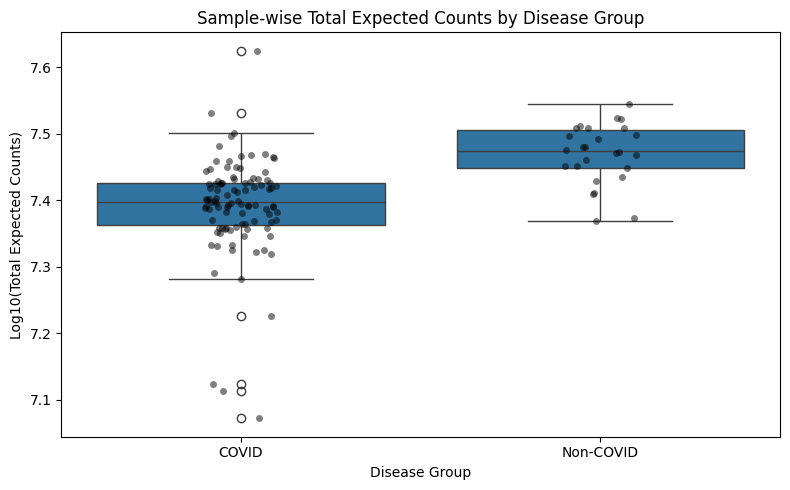

In [ ]:
"""

Do all samples have comparable amounts of gene-expression data, or are there substantial differences between samples?

"""

# STEP 1: Sample-level expression and sequencing depth

# Calculate total expected counts for each sample
total_counts = ec.sum(axis=0)

# Create a sample-level DataFrame
sample_qc = pd.DataFrame({
    "Sample": ec.columns,
    "Total_EC": total_counts.values,
    "Disease": meta.loc[ec.columns, "Disease"].values,
    "ICU": meta.loc[ec.columns, "ICU"].values
})

# Log-transform total counts for easier visualization
sample_qc["Log_Total_EC"] = np.log10(sample_qc["Total_EC"])

# Print summary statistics
print("Overall sequencing depth summary:")
print(sample_qc["Total_EC"].describe())

print("\nSequencing depth by disease group:")
print(sample_qc.groupby("Disease")["Total_EC"].describe())

# Plot total expected counts by disease group
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=sample_qc,
    x="Disease",
    y="Log_Total_EC"
)

sns.stripplot(
    data=sample_qc,
    x="Disease",
    y="Log_Total_EC",
    color="black",
    alpha=0.5,
    jitter=True
)

plt.title("Sample-wise Total Expected Counts by Disease Group")
plt.xlabel("Disease Group")
plt.ylabel("Log10(Total Expected Counts)")
plt.tight_layout()
plt.show()

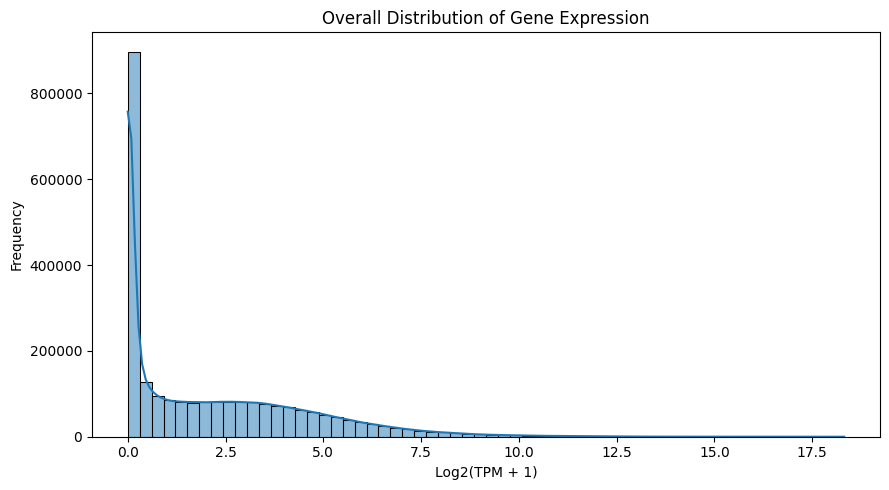

Expression distribution:
count    2.453472e+06
mean     2.118304e+00
std      2.370077e+00
min      0.000000e+00
25%      2.856915e-02
50%      1.304511e+00
75%      3.632268e+00
max      1.831711e+01
dtype: float64

Zero expression values: 548695
Total expression values: 2453472
Percentage of zero TPM values: 22.36 %


In [ ]:
# STEP 2: Overall gene expression distribution

# Log-transform TPM
log_tpm = np.log2(tpm + 1)

# Flatten all expression values
all_expression = log_tpm.values.flatten()

# Plot histogram
plt.figure(figsize=(9, 5))

sns.histplot(
    all_expression,
    bins=60,
    kde=True
)

plt.title("Overall Distribution of Gene Expression")
plt.xlabel("Log2(TPM + 1)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

# Descriptive statistics
print("Expression distribution:")
print(pd.Series(all_expression).describe())

# Percentage of zero TPM values
zero_count = (tpm == 0).sum().sum()
total_values = tpm.size

print("\nZero expression values:", zero_count)
print("Total expression values:", total_values)
print("Percentage of zero TPM values:",
      round(zero_count / total_values * 100, 2), "%")

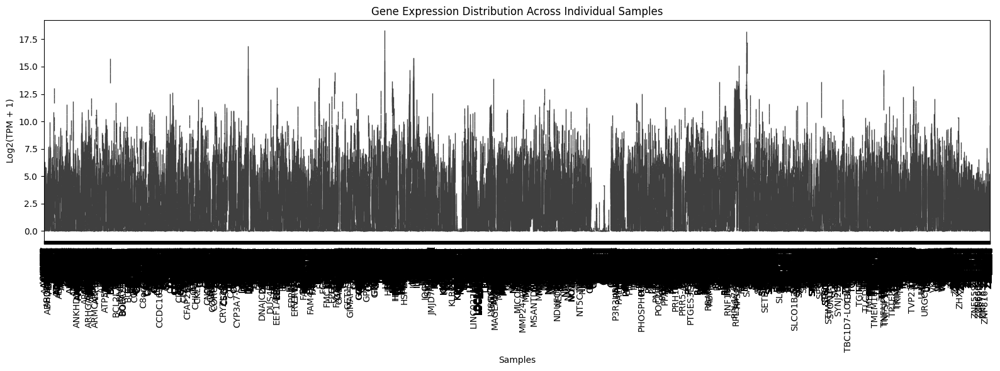

Sample-wise expression summary:


,Mean,Median,Std,Q1,Q3
count,126.000000,126.000000,126.000000,126.000000,126.000000
mean,2.118304,1.358544,2.357411,0.036556,3.593689
std,0.225602,0.371146,0.098732,0.019293,0.425957
min,1.286190,0.411426,1.868026,0.000000,1.938285
25%,1.998748,1.100966,2.304270,0.028569,3.373020
50%,2.128832,1.370162,2.368026,0.033847,3.627590
75%,2.274057,1.641546,2.435549,0.042644,3.890142
max,2.582886,2.195348,2.546052,0.084064,4.459432



5 samples with highest median expression:


,Mean,Median,Std,Q1,Q3
C11,2.563039,2.195348,2.482254,0.084064,4.386811
C69,2.562544,2.181102,2.509755,0.084064,4.385431
C73,2.582886,2.160275,2.546052,0.070389,4.459432
C7,2.530194,2.134221,2.473351,0.084064,4.314153
C57,2.500037,2.107688,2.455099,0.084064,4.258519



5 samples with lowest median expression:


,Mean,Median,Std,Q1,Q3
C50,1.286190,0.411426,1.868026,0.000000,1.938285
NC26,1.461397,0.505891,2.029235,0.000000,2.266037
NC3,1.766174,0.713696,2.255990,0.000000,2.956057
C99,1.753615,0.748461,2.248351,0.014355,2.865919
C76,1.796445,0.765535,2.236030,0.000000,3.089159


In [ ]:
# STEP 3: Expression distribution across individual samples

# Transpose log TPM so that samples are rows
log_tpm_samples = log_tpm.T

# Create boxplot
plt.figure(figsize=(16, 6))

sns.boxplot(
    data=log_tpm_samples,
    color="skyblue",
    showfliers=False
)

plt.title("Gene Expression Distribution Across Individual Samples")
plt.xlabel("Samples")
plt.ylabel("Log2(TPM + 1)")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Calculate sample-wise statistics
sample_expression_summary = pd.DataFrame({
    "Mean": log_tpm_samples.mean(axis=1),
    "Median": log_tpm_samples.median(axis=1),
    "Std": log_tpm_samples.std(axis=1),
    "Q1": log_tpm_samples.quantile(0.25, axis=1),
    "Q3": log_tpm_samples.quantile(0.75, axis=1)
})

print("Sample-wise expression summary:")
display(sample_expression_summary.describe())

# Identify samples with the highest and lowest median expression
print("\n5 samples with highest median expression:")
display(sample_expression_summary.nlargest(5, "Median"))

print("\n5 samples with lowest median expression:")
display(sample_expression_summary.nsmallest(5, "Median"))

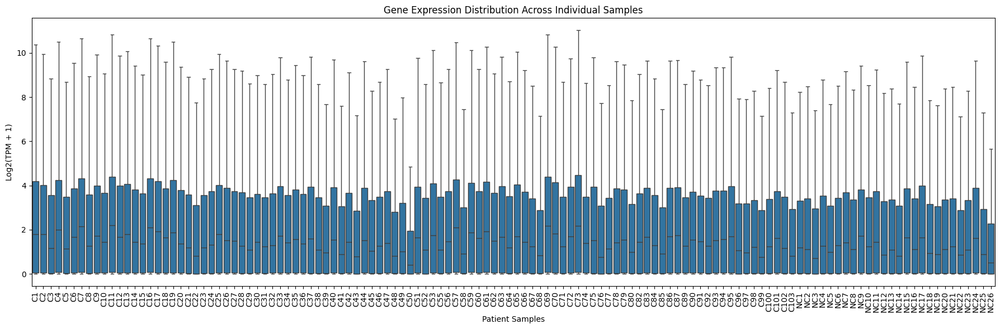

In [ ]:
# Convert expression data into long format
plot_data = log_tpm.T.stack().reset_index()

plot_data.columns = ["Sample", "Gene", "Log2_TPM"]

plt.figure(figsize=(18, 6))

sns.boxplot(
    data=plot_data,
    x="Sample",
    y="Log2_TPM",
    showfliers=False
)

plt.title("Gene Expression Distribution Across Individual Samples")
plt.xlabel("Patient Samples")
plt.ylabel("Log2(TPM + 1)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Gene detection frequency summary:
count    19472.000000
mean        77.635979
std         37.058075
min          0.000000
25%         65.079365
50%        100.000000
75%        100.000000
max        100.000000
Name: Detection_Percentage, dtype: float64

Genes detected in:
All samples: 11847
More than 75% of samples: 14255
Less than 25% of samples: 3510
No samples: 1154


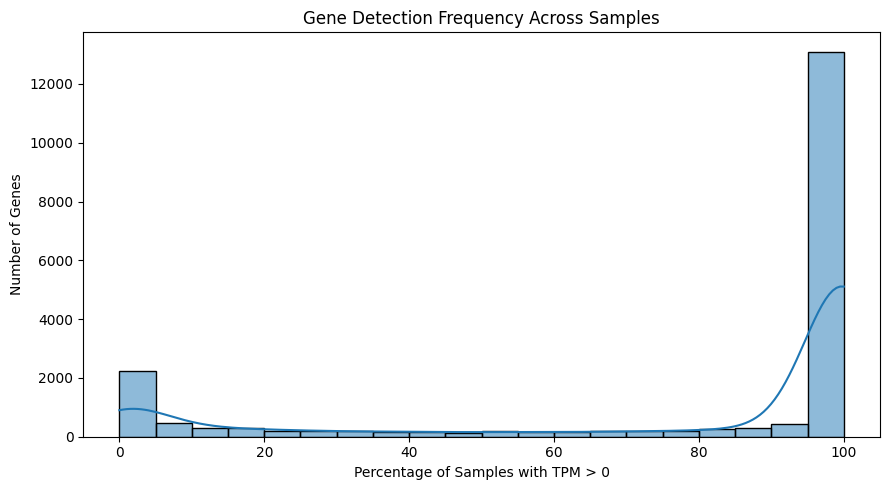

In [ ]:
# STEP 4: Gene detection frequency

# Count the number of samples in which each gene has TPM > 0
gene_detection = (tpm > 0).sum(axis=1)

# Calculate percentage of samples in which each gene is detected
gene_detection_percentage = (gene_detection / tpm.shape[1]) * 100

# Create summary DataFrame
detection_summary = pd.DataFrame({
    "Samples_Detected": gene_detection,
    "Detection_Percentage": gene_detection_percentage
})

# Categorise genes based on detection frequency
print("Gene detection frequency summary:")
print(detection_summary["Detection_Percentage"].describe())

print("\nGenes detected in:")
print("All samples:", (gene_detection == 126).sum())
print("More than 75% of samples:", (gene_detection_percentage > 75).sum())
print("Less than 25% of samples:", (gene_detection_percentage < 25).sum())
print("No samples:", (gene_detection == 0).sum())

# Plot detection frequency
plt.figure(figsize=(9, 5))

sns.histplot(
    gene_detection_percentage,
    bins=20,
    kde=True
)

plt.title("Gene Detection Frequency Across Samples")
plt.xlabel("Percentage of Samples with TPM > 0")
plt.ylabel("Number of Genes")

plt.tight_layout()
plt.show()

Median expression by disease group:
           count      mean       std       min       25%       50%       75%  \
Disease                                                                        
COVID      100.0  1.414493  0.367024  0.411426  1.179500  1.432950  1.663333   
Non-COVID   26.0  1.143356  0.307615  0.505891  0.898925  1.117695  1.272014   

                max  
Disease              
COVID      2.195348  
Non-COVID  1.713696  


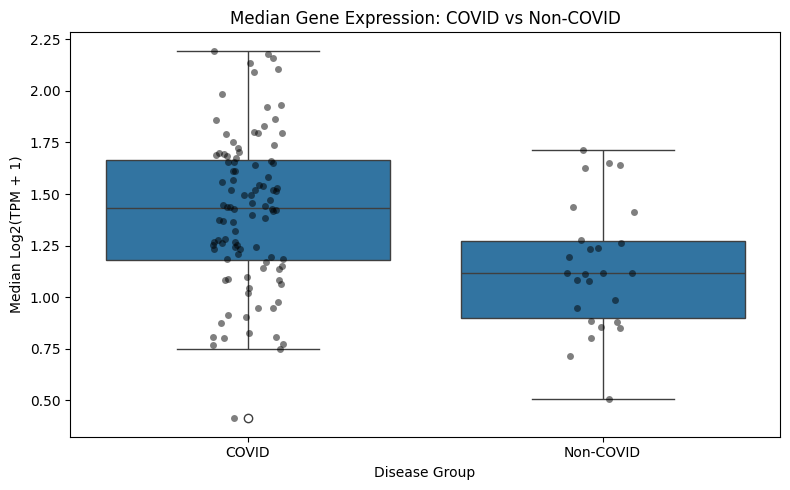

In [ ]:
# STEP 5: Group-wise expression distribution

# Convert TPM to log2 scale
log_tpm = np.log2(tpm + 1)

# Calculate median expression for each sample
sample_medians = log_tpm.median(axis=0)

# Create plotting DataFrame
group_data = pd.DataFrame({
    "Sample": sample_medians.index,
    "Median_Expression": sample_medians.values,
    "Disease": meta.loc[sample_medians.index, "Disease"].values
})

# Print descriptive statistics
print("Median expression by disease group:")
print(group_data.groupby("Disease")["Median_Expression"].describe())

# Boxplot
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=group_data,
    x="Disease",
    y="Median_Expression"
)

sns.stripplot(
    data=group_data,
    x="Disease",
    y="Median_Expression",
    color="black",
    alpha=0.5,
    jitter=True
)

plt.title("Median Gene Expression: COVID vs Non-COVID")
plt.xlabel("Disease Group")
plt.ylabel("Median Log2(TPM + 1)")

plt.tight_layout()
plt.show()

Mean correlation: 0.9539281564843615
Minimum correlation: 0.8199859213534973
Maximum correlation: 0.992401096367033


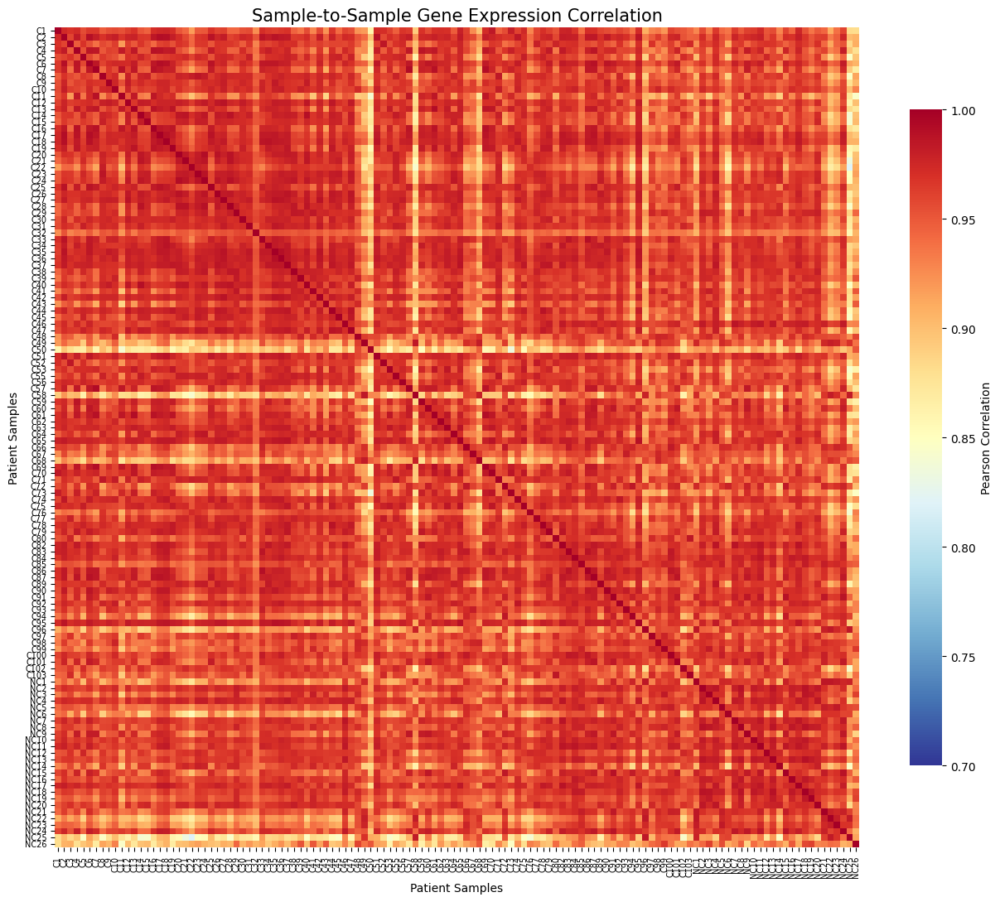

In [ ]:
# STEP 6: Sample-to-sample correlation

# Calculate correlation between samples
sample_corr = log_tpm.corr(method="pearson")

# Display correlation summary
upper_triangle = sample_corr.values[
    np.triu_indices_from(sample_corr, k=1)
]

print("Mean correlation:", upper_triangle.mean())
print("Minimum correlation:", upper_triangle.min())
print("Maximum correlation:", upper_triangle.max())

# Plot heatmap
plt.figure(figsize=(13, 11))

sns.heatmap(
    sample_corr,
    cmap="RdYlBu_r",       # More distinguishable colour gradient
    vmin=0.70,              # Focus on differences among high correlations
    vmax=1.0,
    center=0.85,
    xticklabels=True,
    yticklabels=True,
    linewidths=0,
    cbar_kws={
        "label": "Pearson Correlation",
        "shrink": 0.8
    }
)

plt.title("Sample-to-Sample Gene Expression Correlation", fontsize=15)
plt.xlabel("Patient Samples")
plt.ylabel("Patient Samples")

plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)

plt.tight_layout()
plt.show()

In [ ]:
plt.tight_layout()

plt.savefig(
    "sample_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

Top 20 highly variable genes:


,Mean_Expression,Variance
#symbol,,
RPS4Y1,4.654032,14.768409
IGHG1,8.515553,11.165417
IFI27,5.958796,11.028477
EIF1AY,3.753638,9.614403
DEFA3,9.063581,9.510078
HLA-DRB4,4.279754,9.343109
JCHAIN,8.080407,7.939429
IGLC2,9.920714,7.766150
DEFA1,8.429724,7.611276


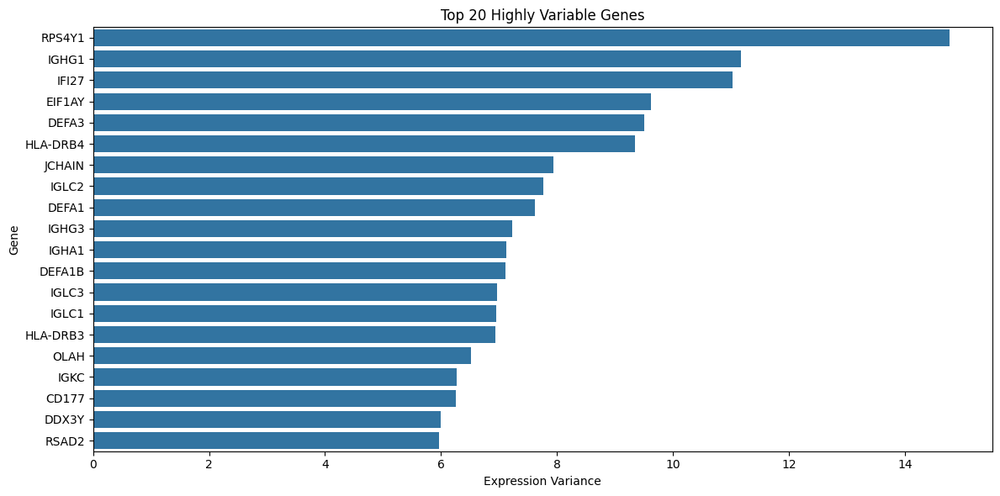

In [ ]:
# STEP 7: Identify highly variable genes

# Calculate mean and variance of log-transformed TPM for each gene
gene_variability = pd.DataFrame({
    "Mean_Expression": log_tpm.mean(axis=1),
    "Variance": log_tpm.var(axis=1)
})

# Sort genes by variance
gene_variability = gene_variability.sort_values(
    by="Variance",
    ascending=False
)

# Display top 20 highly variable genes
top_20_genes = gene_variability.head(20)

print("Top 20 highly variable genes:")
display(top_20_genes)

# Plot top 20 genes
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_20_genes["Variance"].values,
    y=top_20_genes.index
)

plt.title("Top 20 Highly Variable Genes")
plt.xlabel("Expression Variance")
plt.ylabel("Gene")

plt.tight_layout()
plt.show()